## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


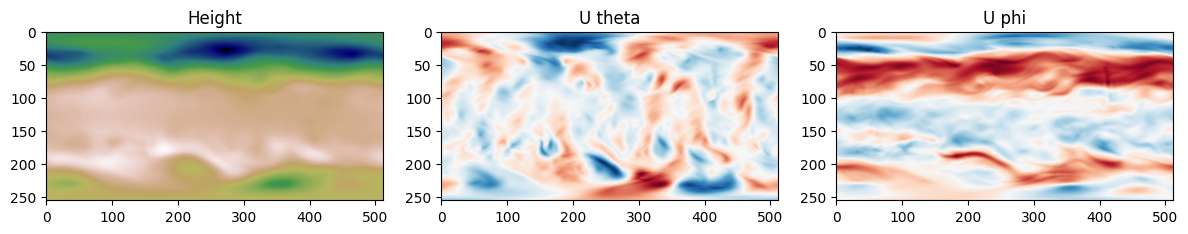

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[157 396]
 [175 151]
 [233 104]
 [221 212]
 [ 94 414]
 [155 357]
 [ 54 198]
 [199 229]
 [152  73]
 [ 95 190]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [157 396]): 193 of 1008 steps masked
Short broken sensor 1 (coord [175 151]): 198 of 1008 steps masked
Short broken sensor 2 (coord [233 104]): 215 of 1008 steps masked
Short broken sensor 3 (coord [221 212]): 208 of 1008 steps masked
Long broken sensor  4 (coord [ 94 414]): steps 340 to 838 masked
Long broken sensor  5 (coord [155 357]): steps 300 to 669 masked
Long broken sensor  6 (coord [ 54 198]): steps 362 to 799 masked
Long broken sensor  7 (coord [199 229]): steps 332 to 936 masked


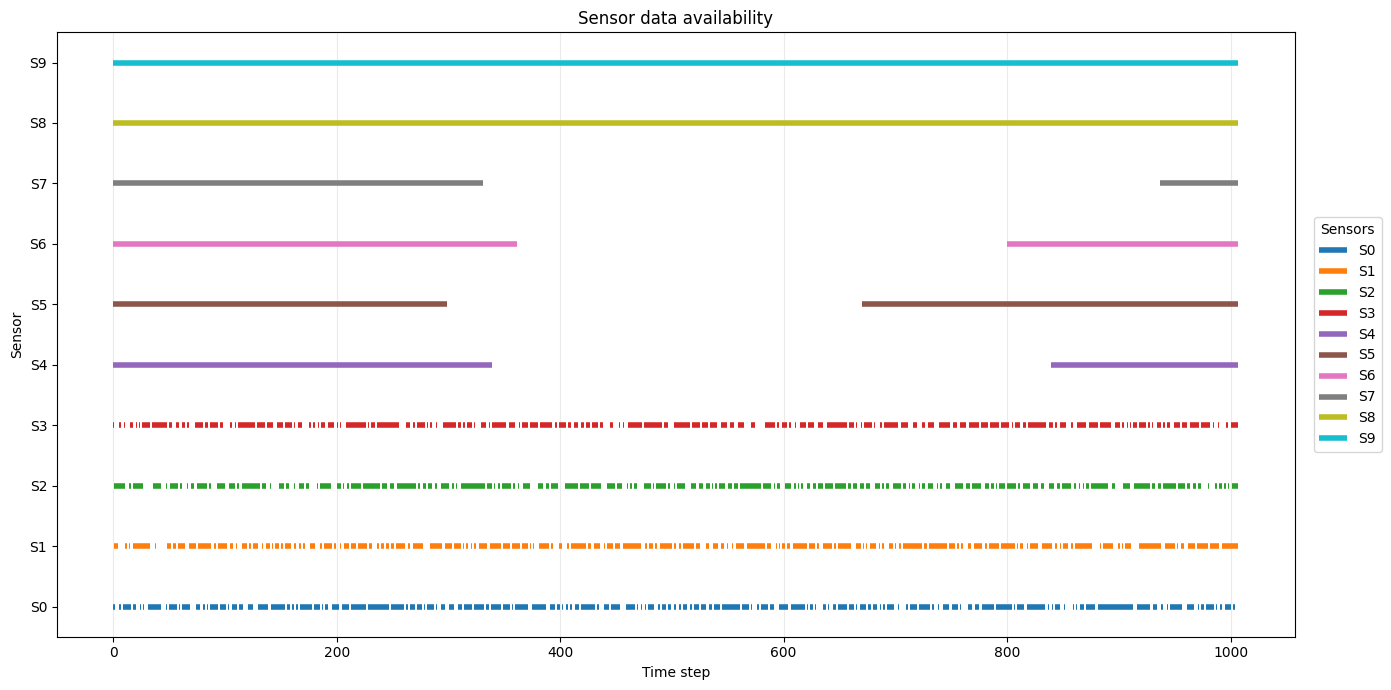

In [6]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~torch.isnan(sensor_data)).to(torch.float32).cpu().numpy()
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

## Check -> USE ROM AS IN SHRED ROM

In [ ]:
np.random.seed(42)  # For reproducibility

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)

H = H.reshape(16, -1, 131072)
sensors_data = sensors_data.reshape(16, -1, 10)

permutation = np.random.permutation(sensors_data.shape[0])
sensors_data = sensors_data[permutation]
H = H[permutation]

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)  

del Utheta, Uphi

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Sensors data shape:	 (16, 126, 10)
H shape:		 (16, 126, 131072)


In [8]:
def plot_reconstruction(
    reconstruction,
    ground_truth,
    Lx,
    Ly,
    field_name="Surface elevation",
    field_unit=None,
    save_path=None,
    dpi=400,
    title_prefix=""
):
    """
    Plot reconstruction, ground truth, and absolute error.

    Parameters
    ----------
    reconstruction : np.ndarray
        Reconstructed field, flattened or already 2D.
    ground_truth : np.ndarray
        Ground-truth field, flattened or already 2D.
    Lx, Ly : int
        Spatial dimensions.
    field_name : str
        Name of the reconstructed field.
    field_unit : str, optional
        Physical unit, e.g. "m".
    save_path : str, optional
        Path where the figure will be saved.
    dpi : int
        Resolution for raster output.
    title_prefix : str
        Prefix for the figure title.
    """

    # Reshape if necessary
    reconstruction = np.asarray(reconstruction).reshape(Lx, Ly)
    ground_truth = np.asarray(ground_truth).reshape(Lx, Ly)

    # Absolute error
    absolute_error = np.abs(reconstruction - ground_truth)

    # Shared scale for reconstruction and ground truth
    vmin = min(reconstruction.min(), ground_truth.min())
    vmax = max(reconstruction.max(), ground_truth.max())

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(20, 4),
        constrained_layout=True
    )

    # Reconstruction
    im0 = axes[0].imshow(
        reconstruction,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[0].set_title(
        f"{title_prefix}",
        fontsize=12,
        fontweight="bold"
    )

    # Ground truth
    im1 = axes[1].imshow(
        ground_truth,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[1].set_title(
        "Ground truth",
        fontsize=12,
        fontweight="bold"
    )

    # Absolute error
    im2 = axes[2].imshow(
        absolute_error,
        cmap="magma",
        vmin=0,
        vmax=absolute_error.max(),
        origin="lower",
        aspect="equal"
    )

    axes[2].set_title(
        "Absolute error",
        fontsize=12,
        fontweight="bold"
    )

    # ---------------------------------------------------------
    # Clean axes
    # ---------------------------------------------------------
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

    # ---------------------------------------------------------
    # Colorbars
    # ---------------------------------------------------------
    field_label = field_name
    if field_unit is not None:
        field_label += f" [{field_unit}]"

    cbar01 = fig.colorbar(
        im1,
        ax=axes[:2],
        fraction=0.025,
        pad=0.02
    )
    cbar01.set_label(field_label, fontsize=10)

    cbar2 = fig.colorbar(
        im2,
        ax=axes[2],
        fraction=0.046,
        pad=0.02
    )
    cbar2.set_label(
        f"Absolute error [{field_unit}]" if field_unit else "Absolute error",
        fontsize=10
    )

    plt.show()

In [9]:
ERRORS = []

# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 250        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.0.A) Always available sensor

In [10]:
always_available_sensors = np.arange(8,10)
print("Always available sensors:\t", always_available_sensors) 
sensors_data = sensors_data[:, :, always_available_sensors]
print("Sensors data shape:\t", sensors_data.shape)

Always available sensors:	 [8 9]
Sensors data shape:	 (16, 126, 2)


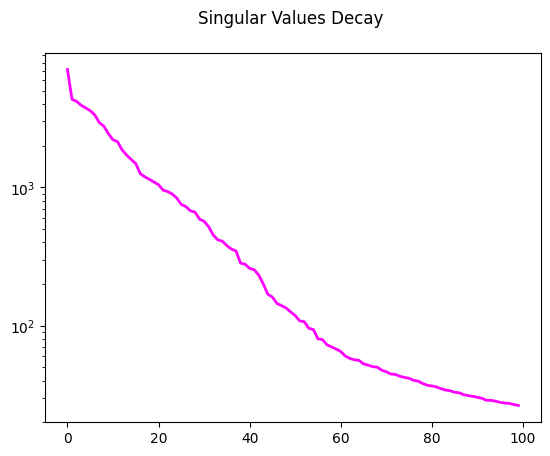

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 2]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 2]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 2]) -> torch.Size([252, 100])

Input shape for the model: 2
Output shape for the model: 100


In [11]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  38%|███▊      | 96/250 [02:08<03:25,  1.34s/it, Train Loss=0.02861, Val Loss=0.03875, Patience=79, Best Val Loss=0.03778, LR=3.36e-04]

Early stopping at epoch 97
Training completed with best validation loss: 0.0378


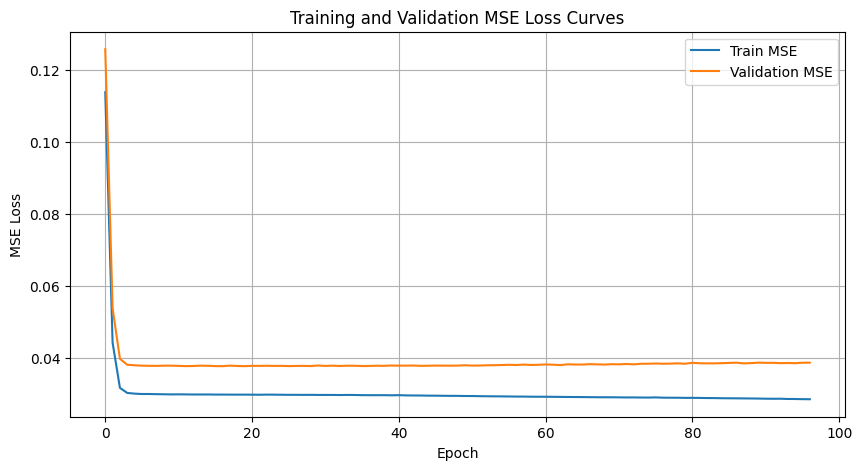

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.0.A): always available sensors,0.029899,0.037783,0.035589,0.347475,0.383429,0.372223,0.174872,0.191621,0.186116


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.0.A): always available sensors"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Starting training...


Training:   0%|          | 0/250 [00:00<?, ?it/s]

Training:  45%|████▌     | 113/250 [00:32<00:39,  3.47it/s, Train Loss=0.02924, Val Loss=0.03906, Patience=79, Best Val Loss=0.03771, LR=2.84e-04]

Early stopping at epoch 114
Training completed with best validation loss: 0.0377


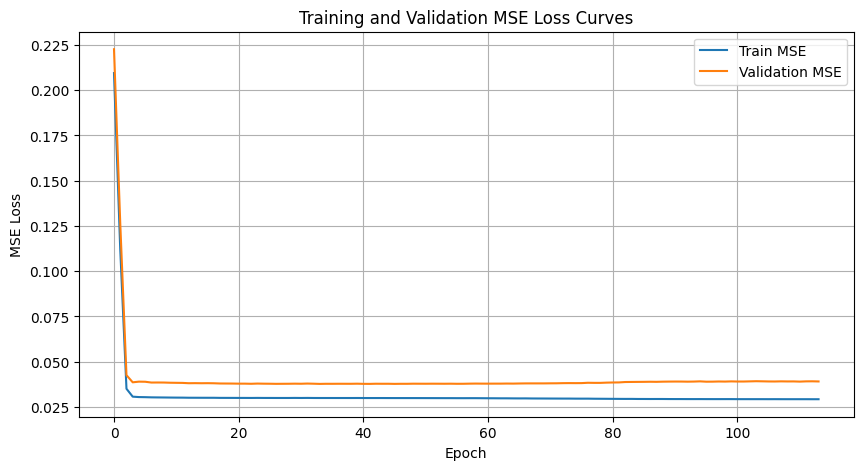

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.0.A): always available sensors,0.029899,0.037783,0.035589,0.347475,0.383429,0.372223,0.174872,0.191621,0.186116
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.029917,0.037710,0.035613,0.347587,0.383031,0.372326,0.174924,0.191436,0.186177


In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="lstm", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, num_layers=ENCODER_DEPTH,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): LSTM+{DECODER}", type="(S.0): always-available stations only"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)